#Environment

In [ ]:
# SPECIFICATION
# Operating System
!printf "%-22s : %s\n" "Operating System" "$(lsb_release -d | awk -F'\t' '{print $2}')"

# Python Version
!printf "%-22s : %s\n" "Python version" "$(python --version 2>&1 | awk '{print $2}')"

# CPU Model
!printf "%-22s : %s\n" "CPU Model" "$(lscpu | grep 'Model name:' | awk -F': ' '{print $2}' | xargs)"

# Memory
!printf "%-22s : %s\n" "Total Memory" "$(free -h | awk '/Mem:/ {print $2}')"
!free -ght

# GPU
!nvidia-smi

Operating System       : Ubuntu 22.04.3 LTS
Python version         : 3.10.12
CPU Model              : Intel(R) Xeon(R) CPU @ 2.20GHz
Total Memory           : 12Gi
               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.8Gi       6.2Gi       1.0Mi       4.6Gi        10Gi
Swap:             0B          0B          0B
Total:          12Gi       1.8Gi       6.2Gi
/bin/bash: line 1: nvidia-smi: command not found


#Library

In [ ]:
# LIBRARY INSTALATION
!pip install top2vec pandas numpy nltk gensim

In [ ]:
#IMPORT LIBRARY
from top2vec import Top2Vec
from gensim.models.coherencemodel import CoherenceModel
from gensim.models import CoherenceModel
from gensim.corpora import Dictionary
from nltk.tokenize import word_tokenize
import pandas as pd
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

#Top2Vec

In [ ]:
#DATASET
# from google.colab import files
# data_test = files.upload()

file_path = '/content/test_with_predictions.csv'
docs = pd.read_csv(file_path, engine='python', encoding= 'utf-8')

In [ ]:
# TOP2VEC
# Memisahkan dokumen berdasarkan hasil prediksi sentimen
# Dokumen akan dibagi menjadi tiga subset: positif, netral, dan negatif
documents = {
    'positive': docs[docs['sentiment_predict'] == 'positive'],
    'neutral': docs[docs['sentiment_predict'] == 'neutral'],
    'negative': docs[docs['sentiment_predict'] == 'negative']
}

# Loop untuk melatih model Top2Vec pada setiap subset sentimen
for label_predict, subset in documents.items():
    print(f"Training Top2Vec model for {label_predict} sentiment...")

    # Mengubah kolom teks menjadi daftar untuk diproses oleh Top2Vec
    documents = subset['text'].tolist()

    # Latih model Top2Vec
    # speed='deep-learn': menggunakan pembelajaran mendalam untuk akurasi tinggi
    # min_count=10: hanya mempertahankan kata yang muncul setidaknya 10 kali
    model = Top2Vec(
        documents,
        speed='deep-learn',
        min_count=10
    )

    # Simpan model hasil pelatihan ke dalam file
    # Nama file disesuaikan dengan label sentimen
    model.save(f"model_top2vec_{label_predict}")

    # Menampilkan jumlah topik yang ditemukan oleh model
    num_topics = model.get_num_topics()
    print(f'Jumlah topik yang ditemukan untuk {label_predict}: {num_topics}')

2024-12-11 12:27:11,297 - top2vec - INFO - Pre-processing documents for training
INFO:top2vec:Pre-processing documents for training
/usr/local/lib/python3.10/dist-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
2024-12-11 12:27:11,318 - top2vec - INFO - Downloading all-MiniLM-L6-v2 model
INFO:top2vec:Downloading all-MiniLM-L6-v2 model


Training Top2Vec model for positive sentiment...


2024-12-11 12:27:12,341 - top2vec - INFO - Creating joint document/word embedding
INFO:top2vec:Creating joint document/word embedding
2024-12-11 12:27:16,139 - top2vec - INFO - Creating lower dimension embedding of documents
INFO:top2vec:Creating lower dimension embedding of documents
2024-12-11 12:27:17,393 - top2vec - INFO - Finding dense areas of documents
INFO:top2vec:Finding dense areas of documents
2024-12-11 12:27:17,414 - top2vec - INFO - Finding topics
INFO:top2vec:Finding topics
2024-12-11 12:27:17,448 - top2vec - INFO - Pre-processing documents for training
INFO:top2vec:Pre-processing documents for training
/usr/local/lib/python3.10/dist-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
2024-12-11 12:27:17,472 - top2vec - INFO - Downloading all-MiniLM-L6-v2 model
INFO:top2vec:Downloading all-MiniLM-L6-v2 model


Jumlah topik yang ditemukan untuk positive: 2
Training Top2Vec model for neutral sentiment...


2024-12-11 12:27:17,837 - top2vec - INFO - Creating joint document/word embedding
INFO:top2vec:Creating joint document/word embedding
2024-12-11 12:27:20,880 - top2vec - INFO - Creating lower dimension embedding of documents
INFO:top2vec:Creating lower dimension embedding of documents
2024-12-11 12:27:21,548 - top2vec - INFO - Finding dense areas of documents
INFO:top2vec:Finding dense areas of documents
2024-12-11 12:27:21,563 - top2vec - INFO - Finding topics
INFO:top2vec:Finding topics
2024-12-11 12:27:21,585 - top2vec - INFO - Pre-processing documents for training
INFO:top2vec:Pre-processing documents for training
/usr/local/lib/python3.10/dist-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
2024-12-11 12:27:21,668 - top2vec - INFO - Downloading all-MiniLM-L6-v2 model
INFO:top2vec:Downloading all-MiniLM-L6-v2 model


Jumlah topik yang ditemukan untuk neutral: 2
Training Top2Vec model for negative sentiment...


2024-12-11 12:27:21,954 - top2vec - INFO - Creating joint document/word embedding
INFO:top2vec:Creating joint document/word embedding
2024-12-11 12:27:46,851 - top2vec - INFO - Creating lower dimension embedding of documents
INFO:top2vec:Creating lower dimension embedding of documents
2024-12-11 12:27:54,407 - top2vec - INFO - Finding dense areas of documents
INFO:top2vec:Finding dense areas of documents
2024-12-11 12:27:54,480 - top2vec - INFO - Finding topics
INFO:top2vec:Finding topics


Jumlah topik yang ditemukan untuk negative: 2


Aspek 0: indonesia, jaya, kerja, kota, nusantara, bawa, dukung, pindah, bangun, kalimantan, maju, jokowi, jalan, perata, tanah, negara, lancar, otorita, harap, rakyat, mudah, tuju, bangsa, sehat, negeri, moga, cita, bagus, ikn, mantap, selamat, satu, nya, perintah, provinsi, wujud, tidak, sukses, presiden
Aspek 1: dukung, kerja, pindah, ikn, bangun, nusantara, indonesia, kota, maju, jaya, rakyat, jokowi, bawa, negeri, kalimantan, tanah, negara, lancar, perata, otorita, sehat, harap, mudah, jalan, tuju, bangsa, provinsi, cita, bagus, selamat, sukses, satu, tidak, mantap, wujud, perintah, moga, presiden, nya


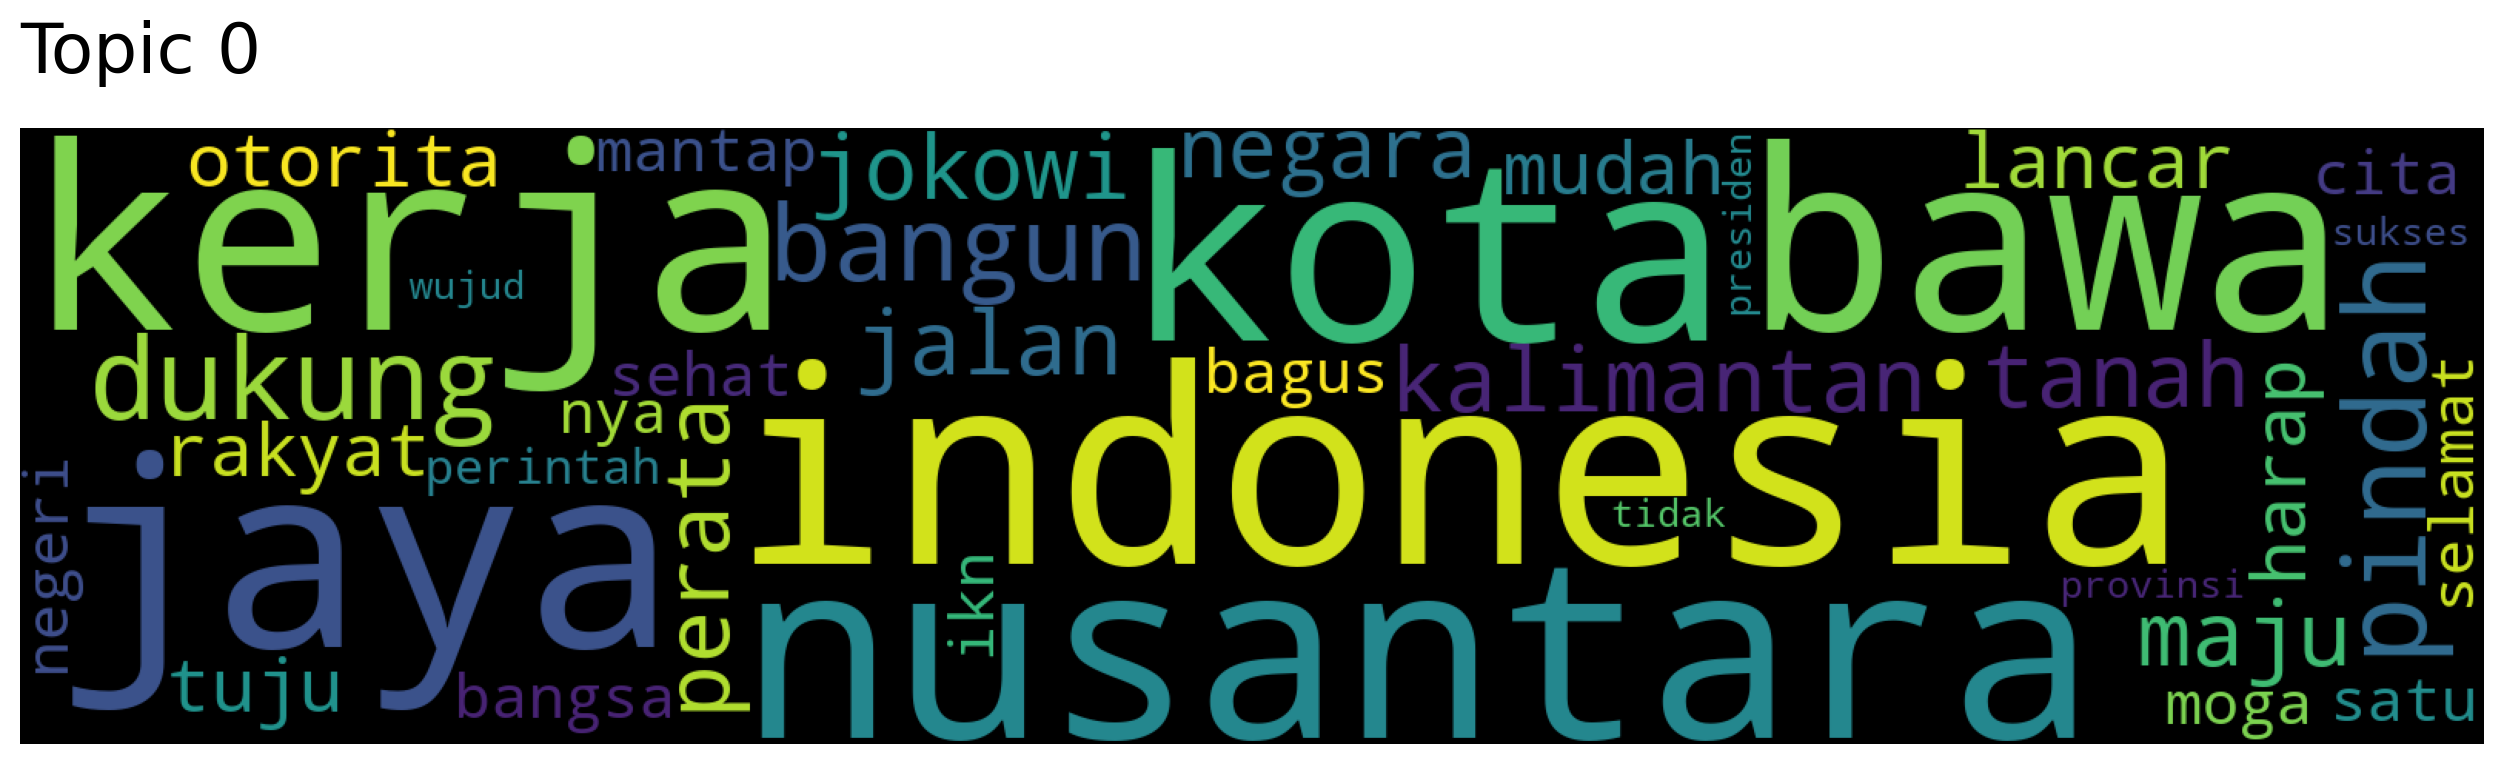

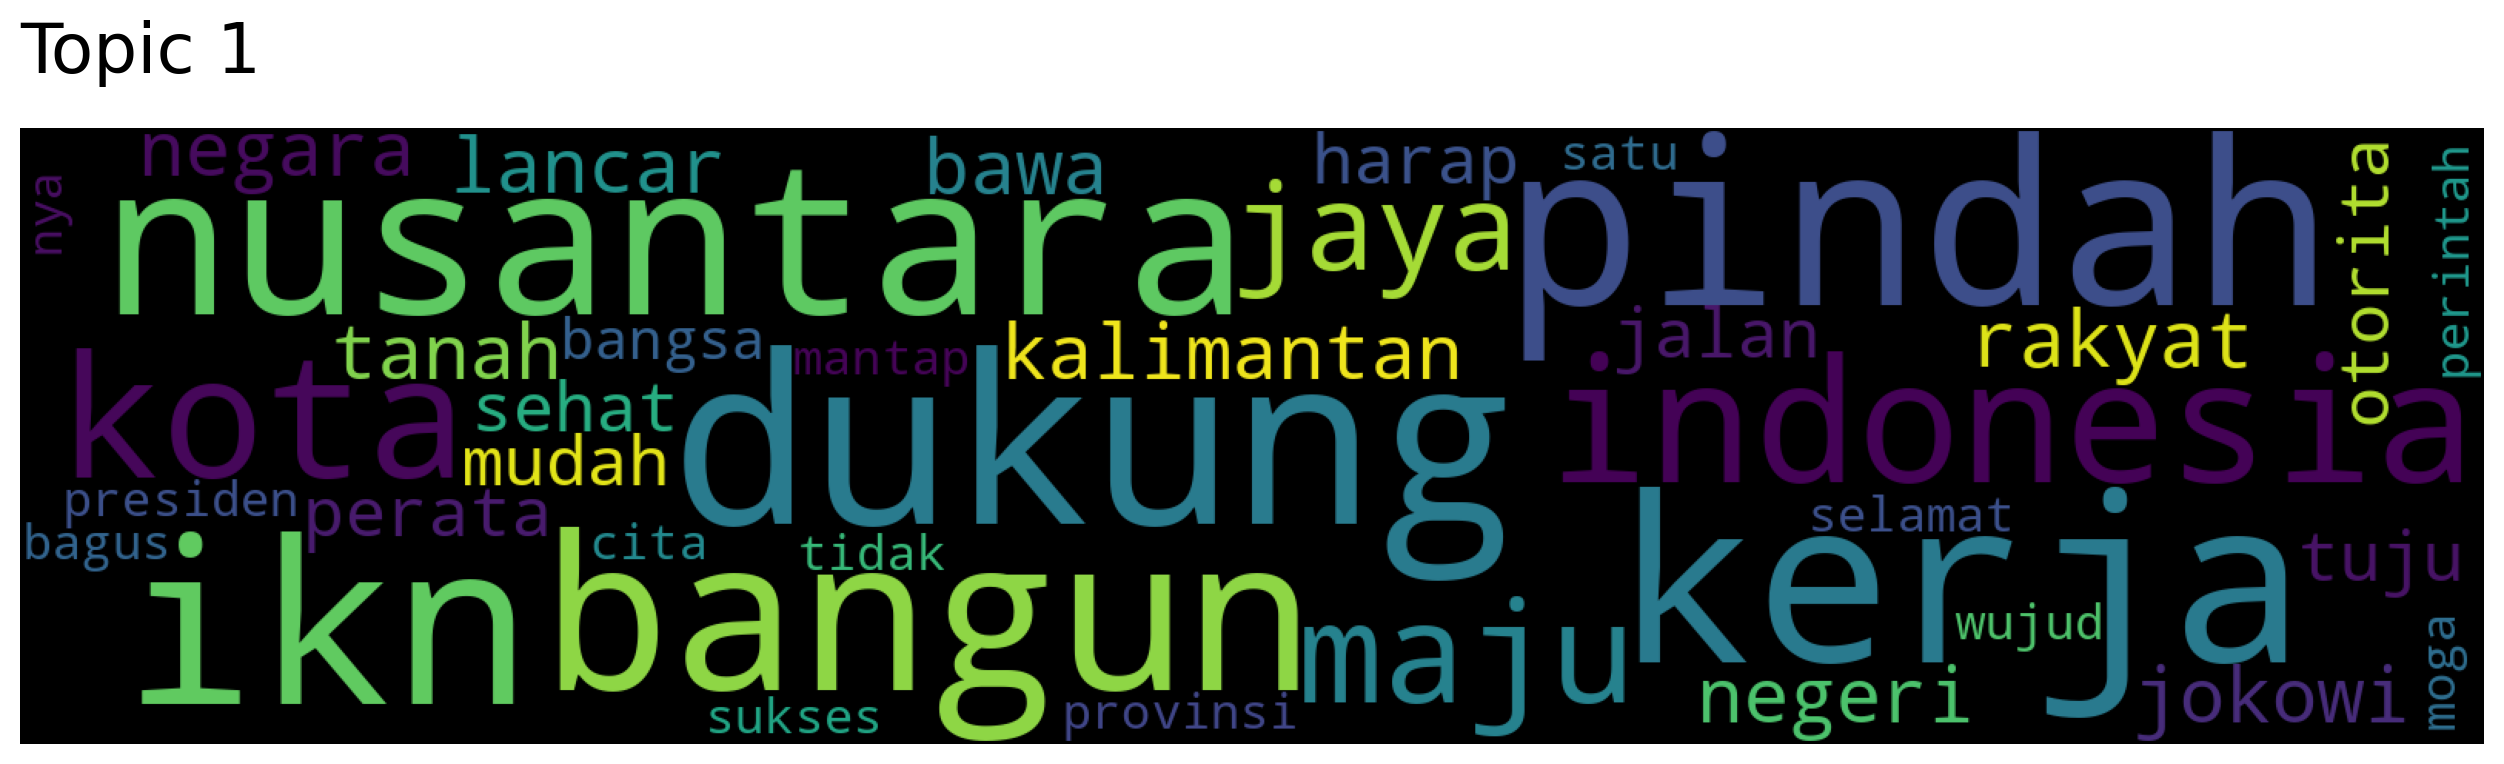

In [ ]:
# POSITIVE TOPIC
# Memuat model Top2Vec untuk sentimen positif dari file yang telah disimpan
model_positive = Top2Vec.load("model_top2vec_positive")

# Mengambil topik, skor kata, dan nomor topik dari model positif
topics_words, word_scores, topic_nums = model_positive.get_topics()

# Menampilkan topik-topik yang ditemukan pada sentimen positif
for topic_id, words in enumerate(topics_words):
    print(f"Aspek {topic_id}: {', '.join(words)}")
    # Membuat word cloud untuk setiap topik
    model_positive.generate_topic_wordcloud(topic_id)

Aspek 0: kepala, jakarta, indonesia, ikn, kota, titik, bukan, jokowi, bawa, pindah, nusantara, kemah, kalimantan, tanah, proyek, jawa, negara, bangun, gubernur, asn, nya, presiden
Aspek 1: ikn, titik, proyek, asn, tanah, kota, jokowi, gubernur, kepala, bawa, jawa, nya, bukan, negara, kemah, jakarta, bangun, indonesia, nusantara, presiden, pindah, kalimantan


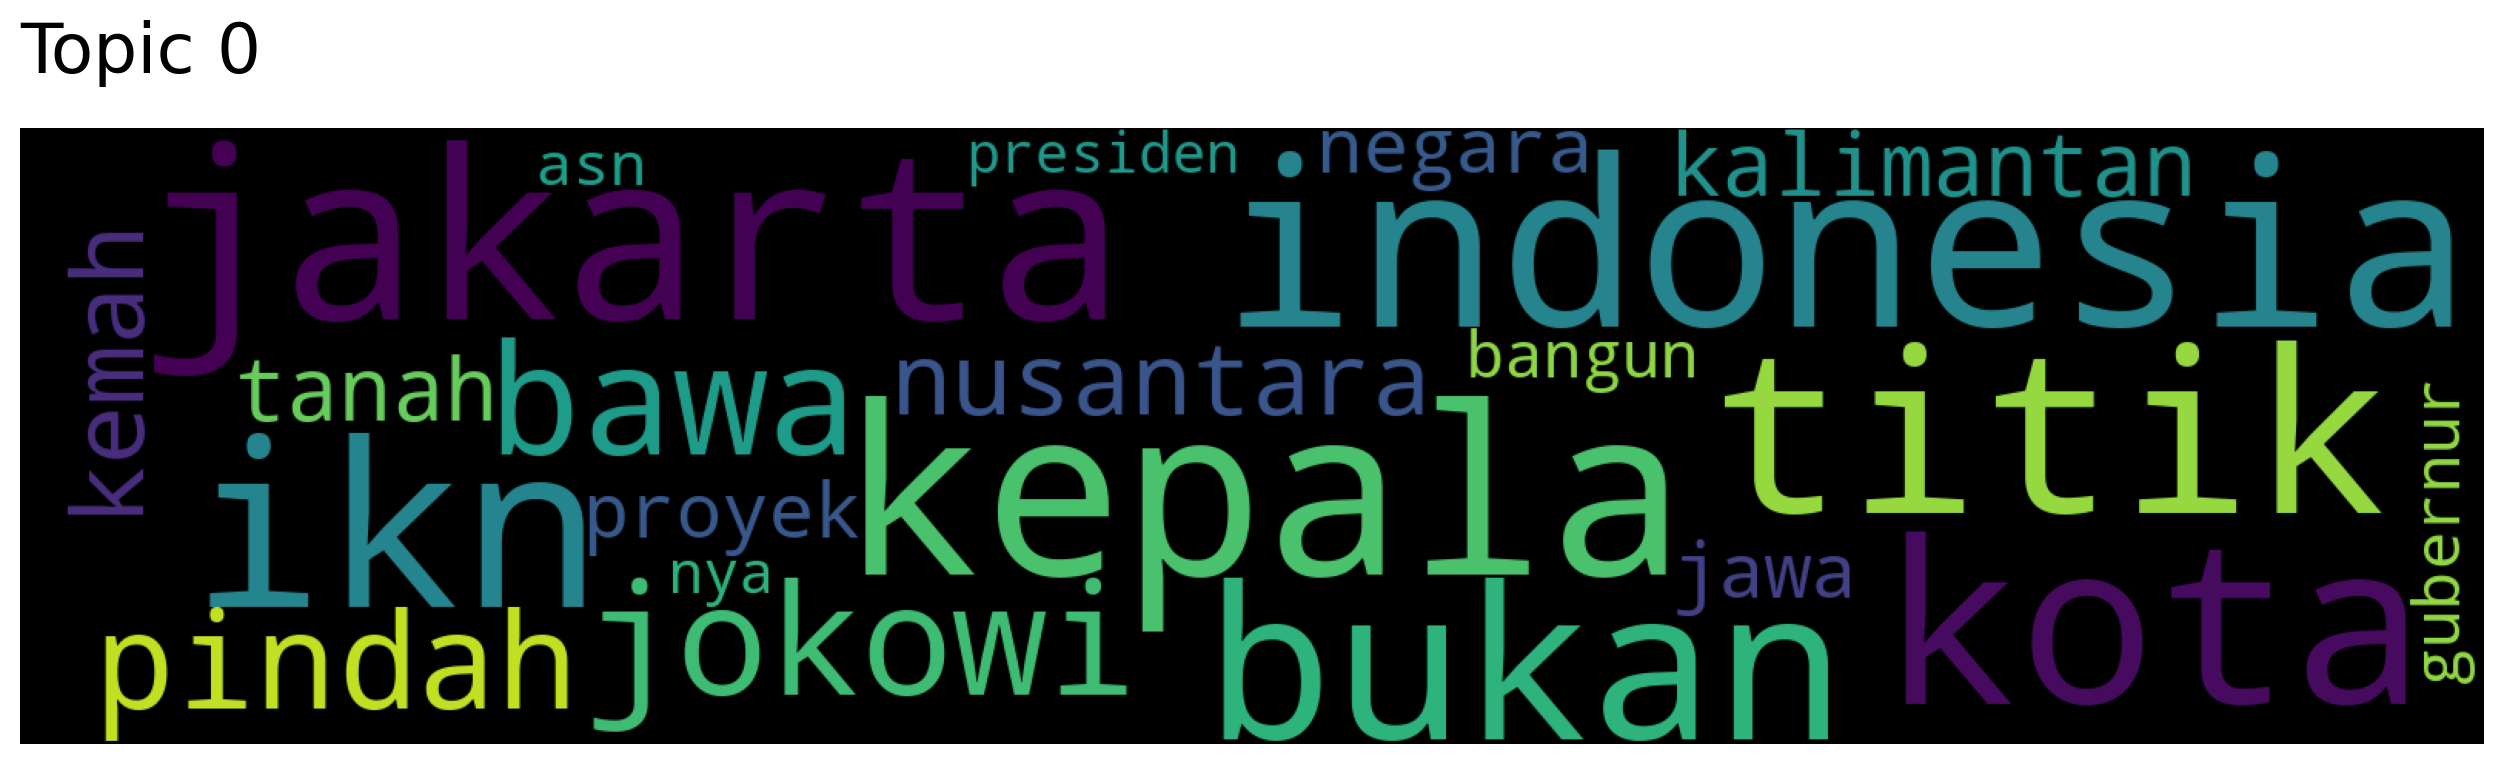

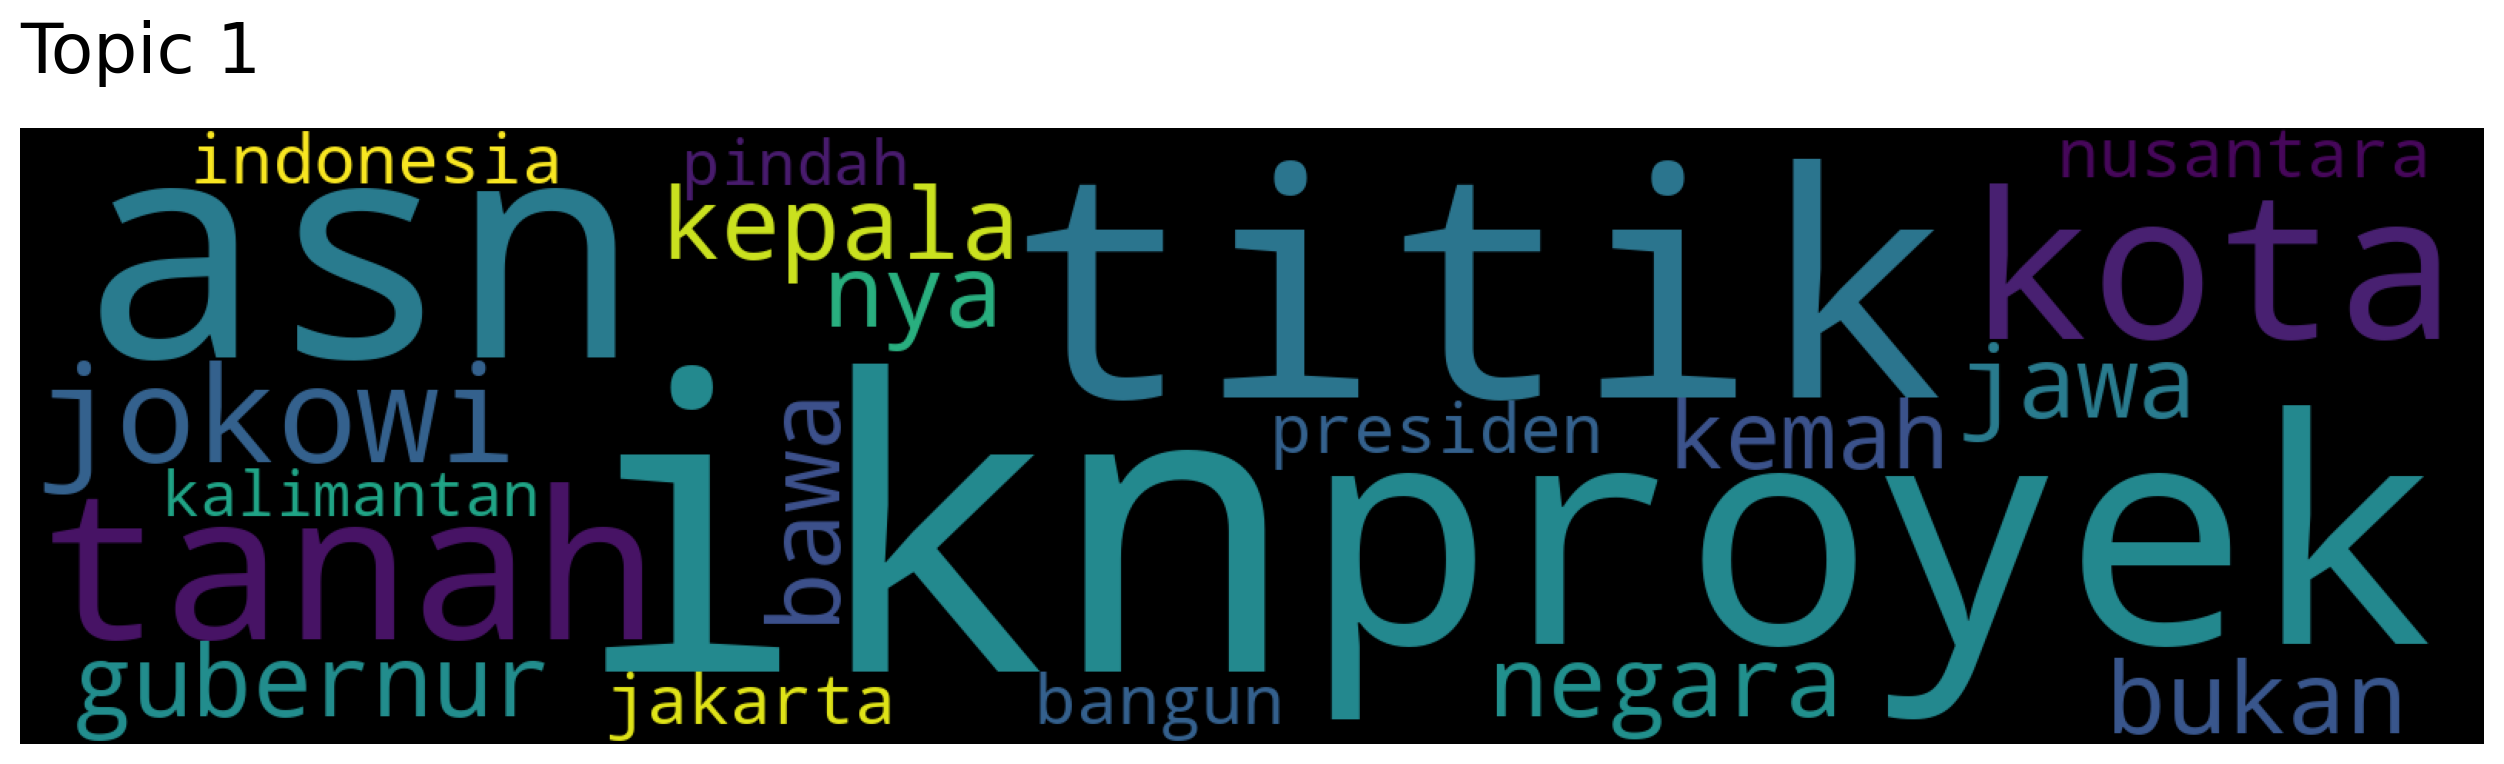

In [ ]:
# NEUTRAL TOPIC
# Memuat model Top2Vec untuk sentimen netral dari file yang telah disimpan
model_neutral = Top2Vec.load("model_top2vec_neutral")

# Mengambil topik, skor kata, dan nomor topik dari model netral
topics_words, word_scores, topic_nums = model_neutral.get_topics()

# Menampilkan topik-topik yang ditemukan pada sentimen netral
for topic_id, words in enumerate(topics_words):
    print(f"Aspek {topic_id}: {', '.join(words)}")
    # Membuat word cloud untuk setiap topik
    model_neutral.generate_topic_wordcloud(topic_id)

Aspek 0: masyarakat, langka, tak, kasih, utang, kagak, lantik, biaya, hubung, kerja, indonesia, ngutang, paksa, bukti, jakarta, langsung, hutang, kau, pajak, barang, kondisi, mangkrak, dukung, pakai, kepala, konstitusi, utama, sejarah, otak, ekonomi, kadrun, budaya, ibukota, suka, ngotot, dukun, titik, korupsi, angkat, istana, perang, kembang, bukan, doang, esemka, tunggu, bijak, buang, bawa, suruh
Aspek 1: softbank, investasi, bukti, masyarakat, biaya, utang, kasih, langka, hubung, indonesia, ibukota, kagak, langsung, tak, jakarta, kondisi, ngotot, pindah, ekonomi, untung, lantik, kerja, kau, otak, paksa, sakit, barang, kadrun, mangkrak, babat, minyak, konstitusi, suruh, ngutang, kepala, budaya, utama, bukan, lupa, bawa, sejarah, sembako, mahal, bijak, istana, korupsi, hutang, pajak, bilang, jokowi


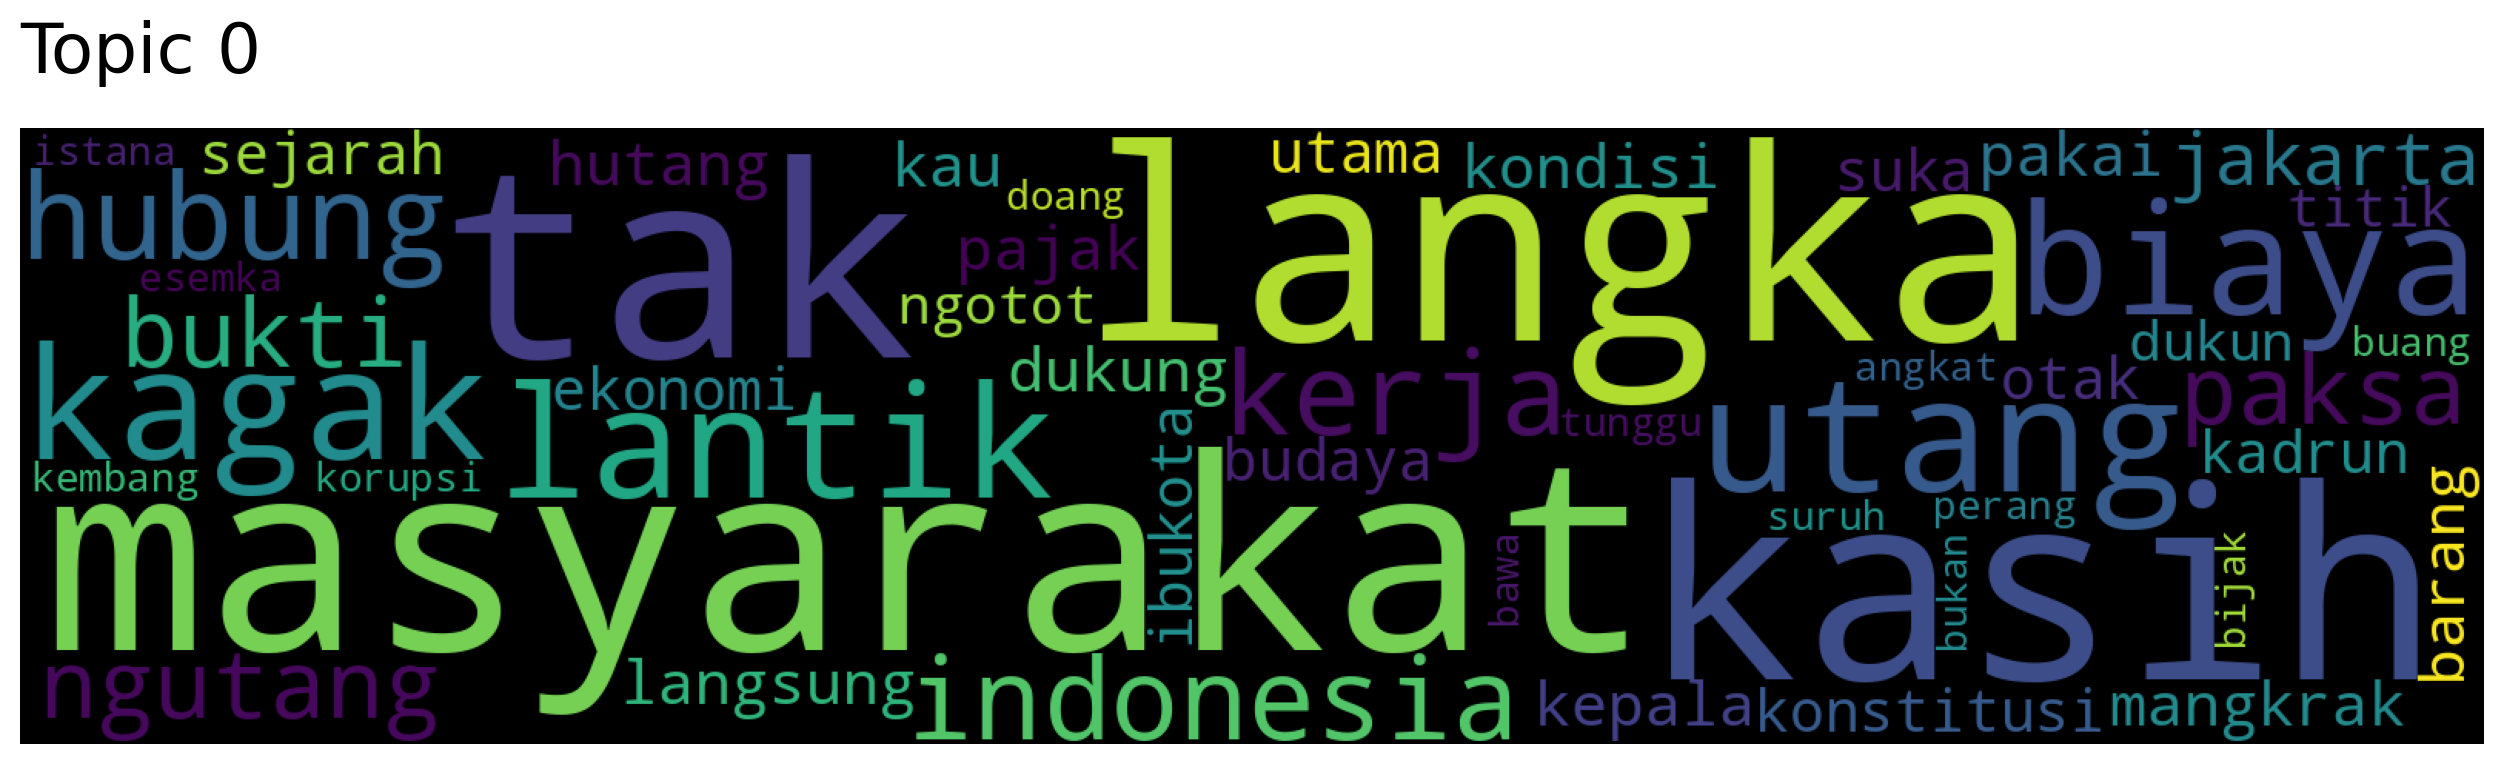

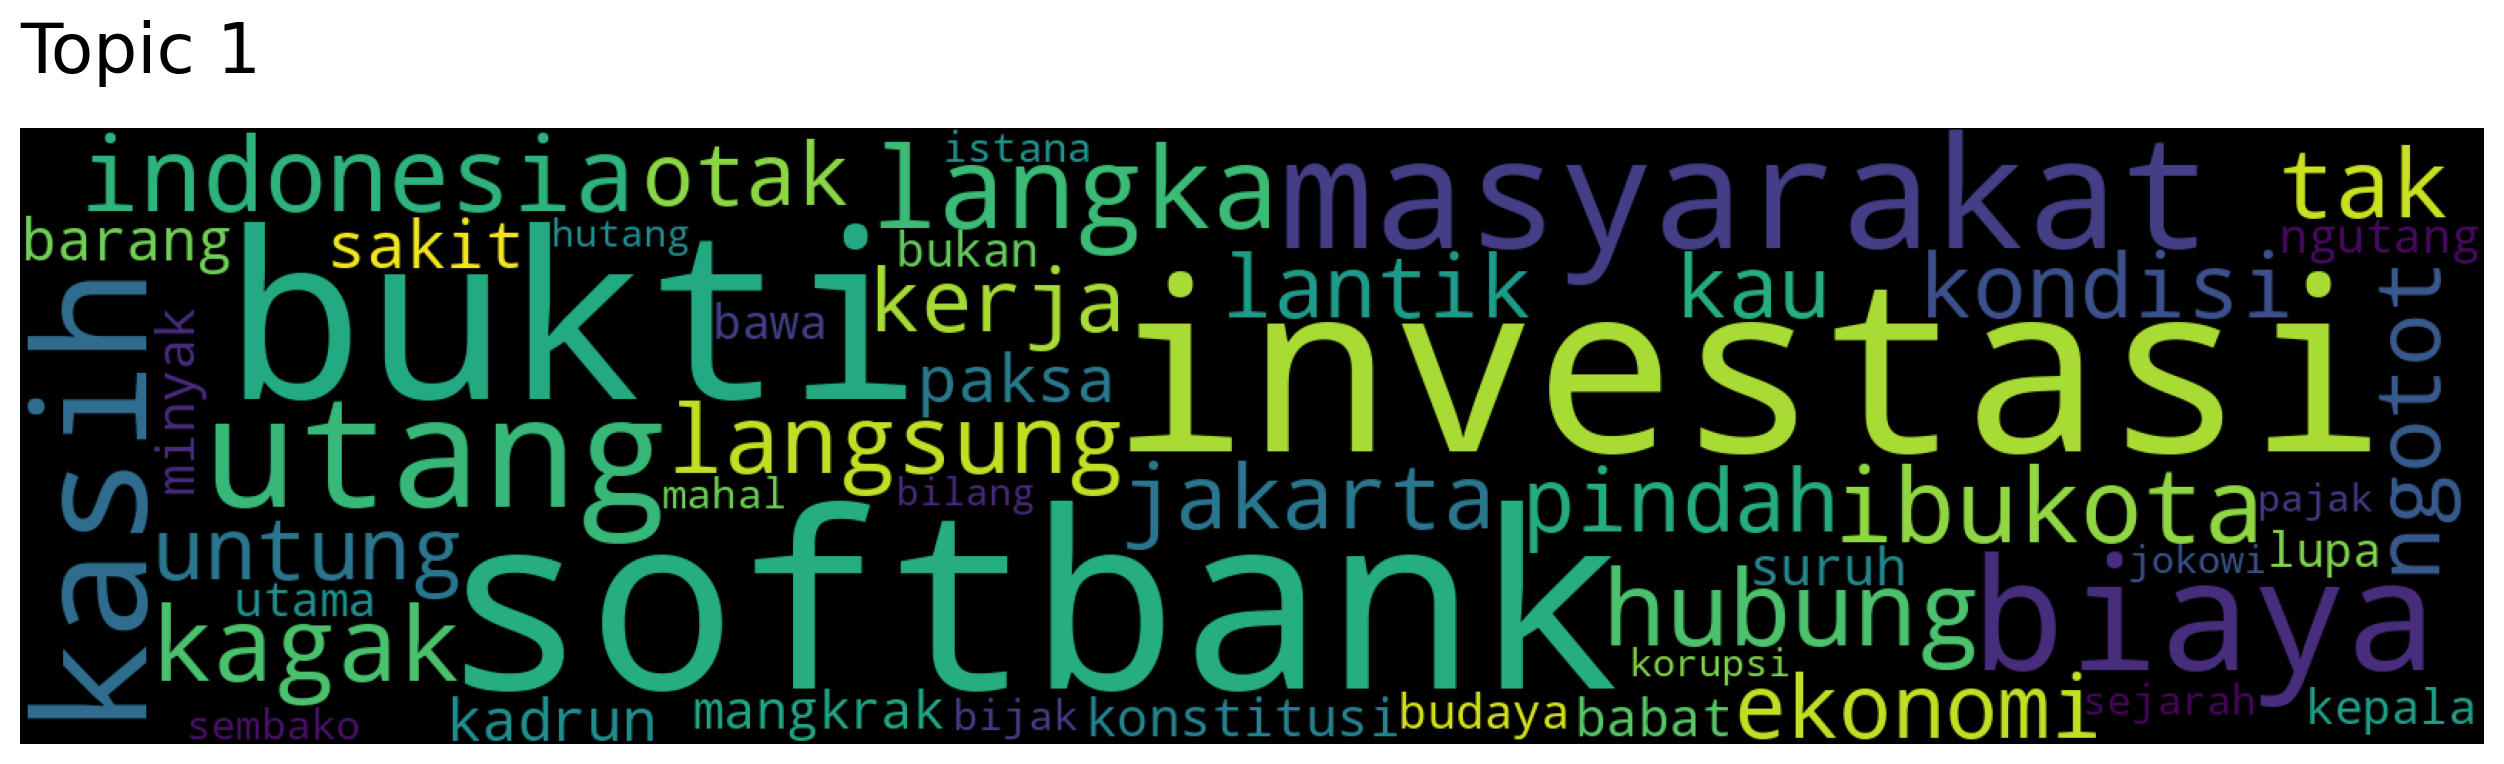

In [ ]:
# NEGATIVE TOPIC
# Memuat model Top2Vec untuk sentimen negatif dari file yang telah disimpan
model_negative = Top2Vec.load("model_top2vec_negative")

# Mengambil topik, skor kata, dan nomor topik dari model negatif
topics_words, word_scores, topic_nums = model_negative.get_topics()

# Menampilkan topik-topik yang ditemukan pada sentimen negatif
for topic_id, words in enumerate(topics_words):
    print(f"Aspek {topic_id}: {', '.join(words)}")
    # Membuat word cloud untuk setiap topik
    model_negative.generate_topic_wordcloud(topic_id)

#Evaluasi Coherence Score

In [ ]:
# TOP2VEC EVALUATION: COHERENCE SCORE
# Dokumen berdasarkan sentimen
documents = {
    'positive': docs[docs['sentiment_predict'] == 'positive']['text'].tolist(),
    'neutral': docs[docs['sentiment_predict'] == 'neutral']['text'].tolist(),
    'negative': docs[docs['sentiment_predict'] == 'negative']['text'].tolist()
}

# Fungsi untuk preprocessing dokumen (tokenisasi)
def preprocess_documents(doc_list):
    return [word_tokenize(doc.lower()) for doc in doc_list]

# Proses dokumen
tokenized_documents = {
    sentiment: preprocess_documents(doc_list)
    for sentiment, doc_list in documents.items()
}

# Membuat dictionary dan corpus untuk setiap sentimen
dictionary_corpus = {
    sentiment: Dictionary(tokens)
    for sentiment, tokens in tokenized_documents.items()
}

corpus = {
    sentiment: [dictionary.doc2bow(tokens) for tokens in tokenized_documents[sentiment]]
    for sentiment, dictionary in dictionary_corpus.items()
}

# Memuat model Top2Vec
models = {
    'positive': Top2Vec.load("model_top2vec_positive"),
    'neutral': Top2Vec.load("model_top2vec_neutral"),
    'negative': Top2Vec.load("model_top2vec_negative")
}

# Menghitung coherence score untuk masing-masing sentimen
coherence_scores = {}

for sentiment, model in models.items():
    topics_words, _, _ = model.get_topics()  # Mendapatkan kata-kata topik
    topics = [[word for word in words] for words in topics_words]

    # Coherence Model
    coherence_model = CoherenceModel(
        topics=topics,
        texts=tokenized_documents[sentiment],
        dictionary=dictionary_corpus[sentiment],
        coherence='c_v'
    )

    # Simpan skor coherence
    coherence_scores[sentiment] = coherence_model.get_coherence()

# Menampilkan hasil
for sentiment, score in coherence_scores.items():
    print(f"Coherence Score untuk {sentiment.capitalize()}: {score:.4f}")


Coherence Score untuk Positive: 0.3180
Coherence Score untuk Neutral: 0.3420
Coherence Score untuk Negative: 0.5136


In [ ]:
# Tambahkan kolom Coherence Score ke DataFrame asli
docs['Coherence_Score'] = docs['sentiment_predict'].map(lambda x: coherence_scores.get(x, None))

# Simpan DataFrame ke file CSV baru
docs.to_csv("test_with_predictions_and_coherence.csv", index=False)
print("File disimpan dengan nama test_with_predictions_and_coherence.csv")

File disimpan dengan nama test_with_predictions_and_coherence.csv
